Język: [English](examples.en.ipynb) | **Polski**

# Wykład 13 — eksperyment: modele dyfuzyjne (DDPM) na danych 2D

Materiał towarzyszący [`lecture.md`](lecture.md). Pięć eksperymentów: (A)
forward diffusion -- zamknięta postać, geometria utraty struktury, rola
ᾱ_T; (B) trening modelu przewidującego szum; (C) reverse diffusion --
generowanie nowych próbek od czystego szumu; (D) noise schedule, liczba
kroków, warunkowanie czasem, jakość predykcji szumu; (E) ocena jakości
generowania. Dane: syntetyczna mieszanina 8 Gaussów na okręgu, generowana
lokalnie -- zero pobrań, zero nowych zależności.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)
device = torch.device("cpu")
print(f"Uzywane urzadzenie: {device}")

notebook_t0 = time.time()

Uzywane urzadzenie: cpu


## A. Forward diffusion

### A.1. Ręczny przykład liczbowy (ten sam, co w `lecture.md`)

In [2]:
T_demo = 10
betas_demo = torch.linspace(1e-4, 0.02, T_demo)
alphas_demo = 1 - betas_demo
alphas_bar_demo = torch.cumprod(alphas_demo, dim=0)

x0 = torch.tensor([2.0, -1.0])
eps_fixed = torch.tensor([0.5, -0.3])

print("t | abar_t | x_t (zamknieta postac)")
for t in [1, 3, 6, 10]:
    abar = alphas_bar_demo[t - 1]
    x_t = torch.sqrt(abar) * x0 + torch.sqrt(1 - abar) * eps_fixed
    print(f"{t:2d} | {abar.item():.4f} | {x_t.tolist()}")

t | abar_t | x_t (zamknieta postac)
 1 | 0.9999 | [2.0049004554748535, -1.0029501914978027]
 3 | 0.9931 | [2.034665584564209, -1.021492838859558]
 6 | 0.9667 | [2.0576725006103516, -1.0379655361175537]
10 | 0.9037 | [2.05643367767334, -1.0437297821044922]


### A.2. Zbiór danych: 8 Gaussów na okręgu

X_train: torch.Size([2000, 2]), mean=tensor([-0.0889,  0.0732]), std=tensor([2.8617, 2.8267])


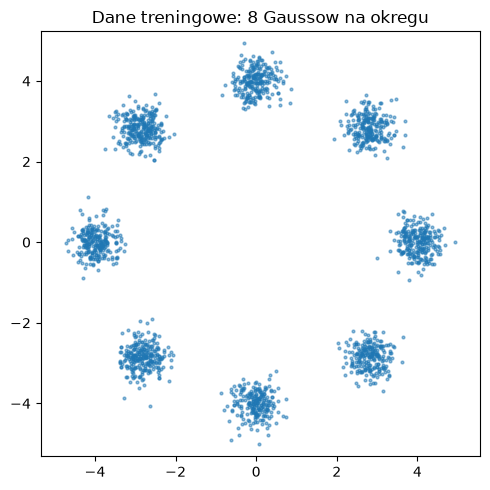

In [3]:
N_COMPONENTS = 8
RADIUS = 4.0
COMPONENT_STD = 0.3


def sample_circle_mixture(n, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    comp = torch.randint(0, N_COMPONENTS, (n,))
    angles = comp.float() * (2 * math.pi / N_COMPONENTS)
    centers = torch.stack([RADIUS * torch.cos(angles), RADIUS * torch.sin(angles)], dim=1)
    return centers + COMPONENT_STD * torch.randn(n, 2)


X_train = sample_circle_mixture(2000, seed=0)
print(f"X_train: {X_train.shape}, mean={X_train.mean(0)}, std={X_train.std(0)}")

plt.figure(figsize=(5, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], s=4, alpha=0.5)
plt.title("Dane treningowe: 8 Gaussow na okregu")
plt.axis("equal")
plt.tight_layout()
plt.show()

### A.3. Harmonogram β i obliczanie ᾱ_t

In [4]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1 - betas
alphas_bar = torch.cumprod(alphas, dim=0)

print(f"T={T}: abar_1={alphas_bar[0].item():.6f}, abar_T={alphas_bar[-1].item():.8f}")
print("-> abar_T bliskie 0: po T krokach sygnal oryginalnych danych jest praktycznie zniszczony")

# porownanie z T=100 (mniej krokow, ten sam zakres beta) -- rola konca harmonogramu
T_short = 100
betas_short = torch.linspace(1e-4, 0.02, T_short)
alphas_bar_short = torch.cumprod(1 - betas_short, dim=0)
print(f"\nT={T_short} (ten sam zakres beta): abar_T={alphas_bar_short[-1].item():.6f}")
print("-> ISTOTNY rezydualny sygnal: rozklad x_T NIE jest bliski N(0,I) dla tej konfiguracji")

T=1000: abar_1=0.999900, abar_T=0.00004036
-> abar_T bliskie 0: po T krokach sygnal oryginalnych danych jest praktycznie zniszczony

T=100 (ten sam zakres beta): abar_T=0.363563
-> ISTOTNY rezydualny sygnal: rozklad x_T NIE jest bliski N(0,I) dla tej konfiguracji


### A.4. Geometryczna utrata struktury

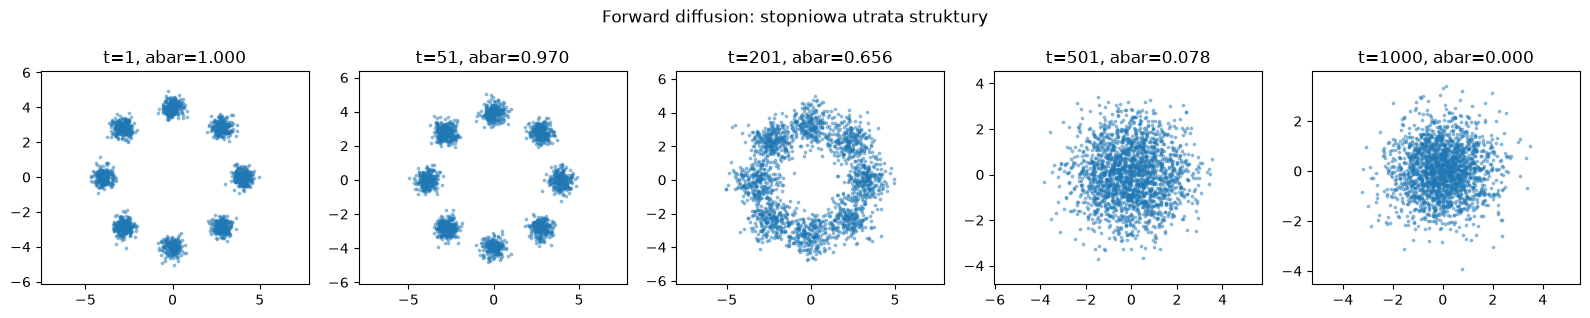

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
demo_ts = [0, 50, 200, 500, 999]
x = X_train.clone()
torch.manual_seed(1)
for i, t_idx in enumerate(demo_ts):
    abar = alphas_bar[t_idx]
    eps = torch.randn_like(X_train)
    x_t = torch.sqrt(abar) * X_train + torch.sqrt(1 - abar) * eps
    axes[i].scatter(x_t[:, 0], x_t[:, 1], s=3, alpha=0.4)
    axes[i].set_title(f"t={t_idx + 1}, abar={abar.item():.3f}")
    axes[i].axis("equal")
fig.suptitle("Forward diffusion: stopniowa utrata struktury")
plt.tight_layout()
plt.show()

### A.5. Weryfikacja: zamknięta postać vs symulacja krok-po-kroku (statystyczna równoważność)

In [6]:
N_TRIALS = 50000
t_check = 300  # 0-indexed

torch.manual_seed(2)
x0_fixed = torch.tensor([3.0, 1.0])
x_stepwise = x0_fixed.unsqueeze(0).repeat(N_TRIALS, 1)
for i in range(t_check + 1):
    noise = torch.randn(N_TRIALS, 2)
    x_stepwise = torch.sqrt(alphas[i]) * x_stepwise + torch.sqrt(betas[i]) * noise

torch.manual_seed(3)
eps_batch = torch.randn(N_TRIALS, 2)
abar_check = alphas_bar[t_check]
x_closed = torch.sqrt(abar_check) * x0_fixed.unsqueeze(0) + torch.sqrt(1 - abar_check) * eps_batch

print(f"t={t_check + 1}, N={N_TRIALS} prob Monte Carlo:")
print(
    f"  stepwise: mean={x_stepwise.mean(0).tolist()}, "
    f"var={x_stepwise.var(0, unbiased=False).tolist()}"
)
print(
    f"  closed:   mean={x_closed.mean(0).tolist()}, var={x_closed.var(0, unbiased=False).tolist()}"
)
print(
    f"  oczekiwane mean: {(torch.sqrt(abar_check) * x0_fixed).tolist()}, "
    f"oczekiwana var: {(1 - abar_check).item():.4f}"
)
print(
    "UWAGA: porownujemy STATYSTYKI (srednia/wariancja), nie pojedyncze probki -- "
    "to dwa niezalezne losowania, nie powinny byc identyczne probka-po-probce."
)

assert torch.allclose(x_stepwise.mean(0), torch.sqrt(abar_check) * x0_fixed, atol=0.02)
assert torch.allclose(x_closed.mean(0), torch.sqrt(abar_check) * x0_fixed, atol=0.02)

t=301, N=50000 prob Monte Carlo:
  stepwise: mean=[1.886418104171753, 0.6252584457397461], var=[0.6097906231880188, 0.6044020652770996]
  closed:   mean=[1.8857895135879517, 0.6342233419418335], var=[0.6022422909736633, 0.6037158370018005]
  oczekiwane mean: [1.8831088542938232, 0.6277029514312744], oczekiwana var: 0.6060
UWAGA: porownujemy STATYSTYKI (srednia/wariancja), nie pojedyncze probki -- to dwa niezalezne losowania, nie powinny byc identyczne probka-po-probce.


## B. Trening modelu przewidującego szum

In [7]:
def sinusoidal_embedding(t, dim=16):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half).float() / half)
    args = t.float().unsqueeze(1) * freqs.unsqueeze(0)
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


class NoisePredictor(nn.Module):
    def __init__(self, time_emb_dim=16, hidden=128):
        super().__init__()
        self.time_emb_dim = time_emb_dim
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t):
        t_emb = sinusoidal_embedding(t, self.time_emb_dim)
        return self.net(torch.cat([x, t_emb], dim=1))


def q_sample(x0, t, eps, abar=alphas_bar):
    a = abar[t].unsqueeze(1)
    return torch.sqrt(a) * x0 + torch.sqrt(1 - a) * eps


def train_ddpm(model, X, T_steps, abar, epochs=200, batch_size=128, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = X.shape[0]
    losses = []
    t0 = time.time()
    for _ in range(epochs):
        perm = torch.randperm(n)
        epoch_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            x0_batch = X[idx]
            b = x0_batch.shape[0]
            t = torch.randint(0, T_steps, (b,))
            eps = torch.randn(b, 2)
            x_t = q_sample(x0_batch, t, eps, abar)
            eps_pred = model(x_t, t)
            loss = F.mse_loss(eps_pred, eps)
            opt.zero_grad()
            loss.backward()
            opt.step()
            epoch_loss += loss.item() * b
        losses.append(epoch_loss / n)
    return time.time() - t0, losses

train_time (200 epok, T=1000): 0.78s
strata (co 20 epok): [0.8619, 0.4035, 0.3605, 0.3578, 0.3743, 0.3471, 0.3471, 0.3432, 0.3276, 0.3086]


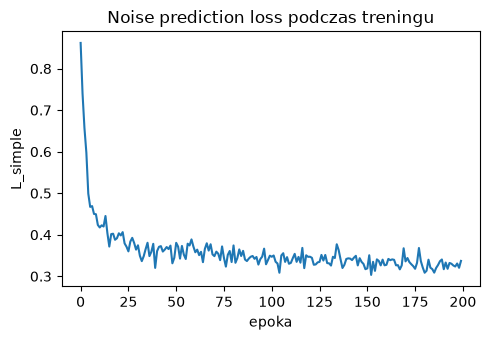

In [8]:
model = NoisePredictor()
train_time, losses = train_ddpm(model, X_train, T, alphas_bar, epochs=200)
print(f"train_time (200 epok, T={T}): {train_time:.2f}s")
print(f"strata (co 20 epok): {[round(losses[i], 4) for i in range(0, 200, 20)]}")

plt.figure(figsize=(5, 3.5))
plt.plot(losses)
plt.xlabel("epoka")
plt.ylabel("L_simple")
plt.title("Noise prediction loss podczas treningu")
plt.tight_layout()
plt.show()

## C. Reverse diffusion — generowanie nowych próbek

**To jest najważniejszy eksperyment wizualny tego modułu.** Zaczynamy od
czystego szumu $x_T\sim N(0,I)$ — nie od zaszumionej wersji żadnego
rzeczywistego przykładu.

In [9]:
def ddpm_reverse_step(model, x, t_idx, alphas, betas, alphas_bar, add_noise):
    t_batch = torch.full((x.shape[0],), t_idx, dtype=torch.long)
    eps_pred = model(x, t_batch)
    alpha_t, beta_t, abar_t = alphas[t_idx], betas[t_idx], alphas_bar[t_idx]
    mu = (1 / torch.sqrt(alpha_t)) * (x - (beta_t / torch.sqrt(1 - abar_t)) * eps_pred)
    if add_noise:
        return mu + torch.sqrt(beta_t) * torch.randn_like(x)
    return mu


@torch.no_grad()
def ddpm_sample(
    model, n_samples, T_steps, alphas, betas, alphas_bar, seed=0, track_trajectory=False
):
    torch.manual_seed(seed)
    x = torch.randn(n_samples, 2)
    trajectory = [x.clone()] if track_trajectory else None
    for t_idx in reversed(range(T_steps)):
        x = ddpm_reverse_step(model, x, t_idx, alphas, betas, alphas_bar, add_noise=(t_idx > 0))
        if track_trajectory:
            trajectory.append(x.clone())
    return x, trajectory

generation time (500 probek, T=1000 krokow): 0.18s
wygenerowane: mean=tensor([-0.4525,  0.0990]), std=tensor([2.8735, 2.8279])


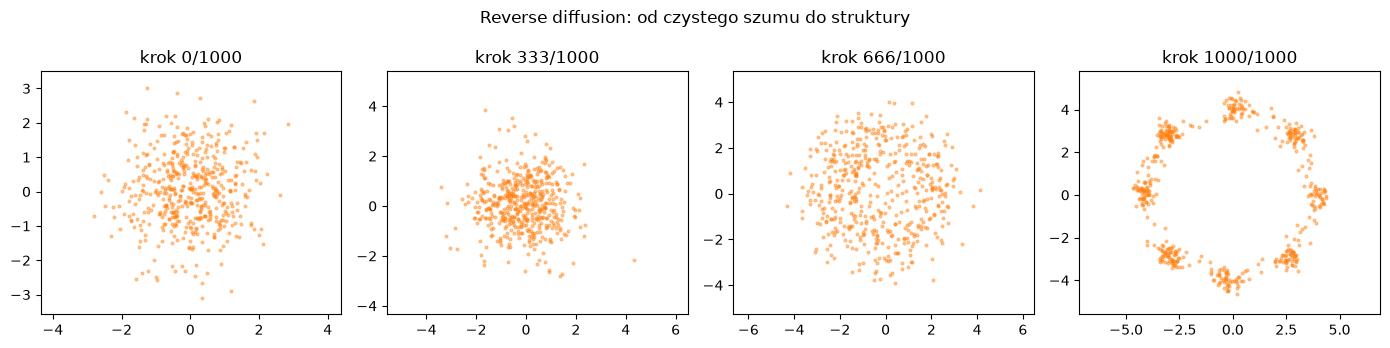

In [10]:
t0 = time.time()
samples, trajectory = ddpm_sample(
    model, 500, T, alphas, betas, alphas_bar, seed=42, track_trajectory=True
)
gen_time = time.time() - t0
print(f"generation time (500 probek, T={T} krokow): {gen_time:.2f}s")
print(f"wygenerowane: mean={samples.mean(0)}, std={samples.std(0)}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
show_steps = [0, T // 3, 2 * T // 3, T]
for i, step in enumerate(show_steps):
    pts = trajectory[step]
    axes[i].scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.4, color="tab:orange")
    axes[i].set_title(f"krok {step}/{T}")
    axes[i].axis("equal")
fig.suptitle("Reverse diffusion: od czystego szumu do struktury")
plt.tight_layout()
plt.show()

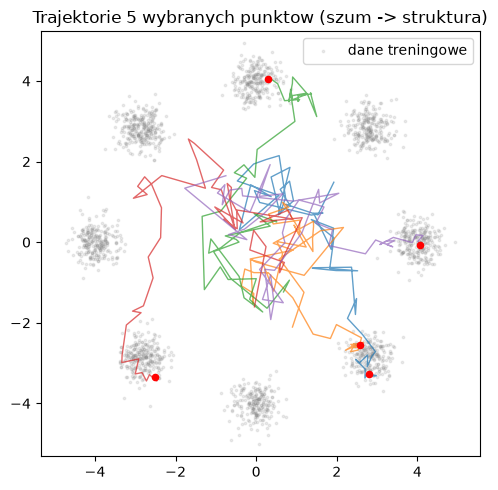

In [11]:
# trajektorie kilku WYBRANYCH pojedynczych punktow (nie caly zbior)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[:, 0], X_train[:, 1], s=3, alpha=0.15, color="gray", label="dane treningowe")
for point_idx in range(5):
    path = torch.stack([trajectory[step][point_idx] for step in range(0, T + 1, max(1, T // 50))])
    ax.plot(path[:, 0], path[:, 1], alpha=0.7, linewidth=1)
    ax.scatter(path[-1, 0], path[-1, 1], color="red", s=20, zorder=5)
ax.set_title("Trajektorie 5 wybranych punktow (szum -> struktura)")
ax.axis("equal")
ax.legend()
plt.tight_layout()
plt.show()

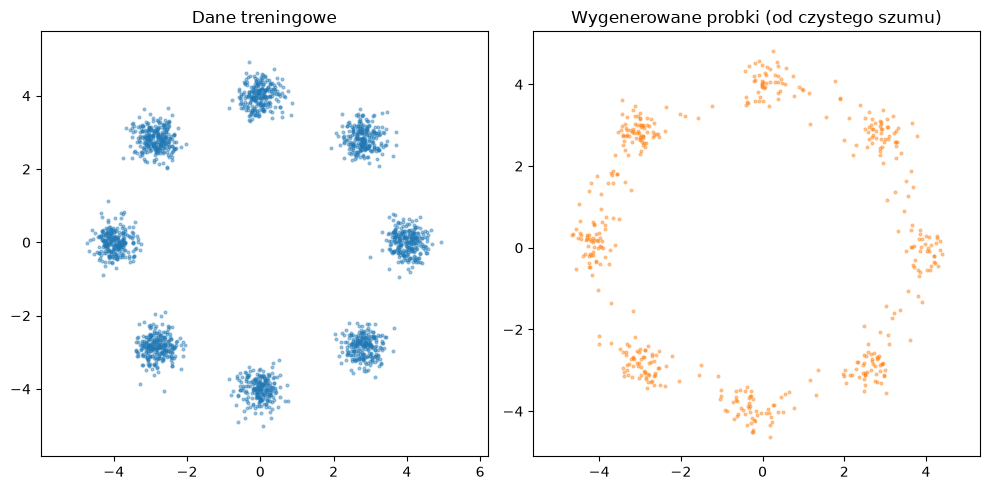

fraction w zasiegu 3*std jakiegos srodka: 0.8680
pokrycie modow: 8/8
srednia odleglosc do najblizszego srodka: 0.5147 (component std=0.3)


In [12]:
# porownanie rozkladu wygenerowanego z rozkladem treningowym
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].scatter(X_train[:, 0], X_train[:, 1], s=4, alpha=0.4)
axes[0].set_title("Dane treningowe")
axes[0].axis("equal")
axes[1].scatter(samples[:, 0], samples[:, 1], s=4, alpha=0.4, color="tab:orange")
axes[1].set_title("Wygenerowane probki (od czystego szumu)")
axes[1].axis("equal")
plt.tight_layout()
plt.show()

angles = torch.arange(N_COMPONENTS).float() * (2 * math.pi / N_COMPONENTS)
centers = torch.stack([RADIUS * torch.cos(angles), RADIUS * torch.sin(angles)], dim=1)


def mode_coverage_metrics(samples):
    dists = torch.cdist(samples, centers)
    min_dists, nearest = dists.min(dim=1)
    frac_near = (min_dists < 3 * COMPONENT_STD).float().mean().item()
    coverage = len(set(nearest[min_dists < 3 * COMPONENT_STD].tolist()))
    return frac_near, coverage, min_dists.mean().item()


frac_near, coverage, mean_dist = mode_coverage_metrics(samples)
print(f"fraction w zasiegu 3*std jakiegos srodka: {frac_near:.4f}")
print(f"pokrycie modow: {coverage}/{N_COMPONENTS}")
print(f"srednia odleglosc do najblizszego srodka: {mean_dist:.4f} (component std={COMPONENT_STD})")

## D. Noise schedule, liczba kroków, warunkowanie czasem

### D.1. Harmonogram cosinusowy vs liniowy

t  | linear abar | cosine abar
 25 | 0.9390      | 0.8470
 50 | 0.7772      | 0.4938
 75 | 0.5666      | 0.1443
100 | 0.3636      | 0.0000


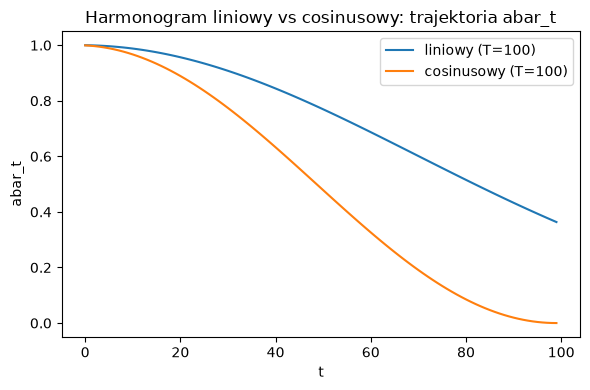

In [13]:
def cosine_schedule(T_steps, s=0.008):
    steps = torch.arange(T_steps + 1).float()
    f = torch.cos(((steps / T_steps + s) / (1 + s)) * math.pi / 2) ** 2
    abar = f / f[0]
    betas_cos = 1 - (abar[1:] / abar[:-1])
    return torch.clamp(betas_cos, 1e-5, 0.999)


betas_cos_100 = cosine_schedule(100)
abar_cos_100 = torch.cumprod(1 - betas_cos_100, dim=0)

print("t  | linear abar | cosine abar")
for t in [25, 50, 75, 100]:
    print(f"{t:3d} | {alphas_bar_short[t - 1].item():.4f}      | {abar_cos_100[t - 1].item():.4f}")

plt.figure(figsize=(6, 4))
plt.plot(alphas_bar_short.numpy(), label="liniowy (T=100)")
plt.plot(abar_cos_100.numpy(), label="cosinusowy (T=100)")
plt.xlabel("t")
plt.ylabel("abar_t")
plt.title("Harmonogram liniowy vs cosinusowy: trajektoria abar_t")
plt.legend()
plt.tight_layout()
plt.show()

### D.2. Poprawne (respaced) vs naiwne próbkowanie z mniejszą liczbą kroków

In [14]:
@torch.no_grad()
def respaced_correct_sample(model, n_samples, T_steps, n_sample_steps, alphas_bar, seed=0):
    indices = torch.linspace(0, T_steps - 1, n_sample_steps).round().long().unique()
    indices = indices.sort(descending=True).values
    torch.manual_seed(seed)
    x = torch.randn(n_samples, 2)
    for i, t_idx in enumerate(indices.tolist()):
        abar_t = alphas_bar[t_idx]
        abar_prev = alphas_bar[indices[i + 1].item()] if i + 1 < len(indices) else torch.tensor(1.0)
        alpha_eff = abar_t / abar_prev
        beta_eff = 1 - alpha_eff
        t_batch = torch.full((n_samples,), t_idx, dtype=torch.long)
        eps_pred = model(x, t_batch)
        mu = (1 / torch.sqrt(alpha_eff)) * (x - (beta_eff / torch.sqrt(1 - abar_t)) * eps_pred)
        x = mu + torch.sqrt(beta_eff) * torch.randn_like(x) if t_idx > 0 else mu
    return x


@torch.no_grad()
def naive_wrong_sample(
    model, n_samples, T_steps, n_sample_steps, alphas, betas, alphas_bar, seed=0
):
    # BUG (deliberately shown WRONG): reuses the single-step alpha_t/beta_t
    # formula for a large skip, as if the skipped steps did not exist.
    indices = torch.linspace(0, T_steps - 1, n_sample_steps).round().long().unique()
    indices = indices.sort(descending=True).values
    torch.manual_seed(seed)
    x = torch.randn(n_samples, 2)
    for t_idx in indices.tolist():
        x = ddpm_reverse_step(model, x, t_idx, alphas, betas, alphas_bar, add_noise=(t_idx > 0))
    return x


print("n_steps | correct frac_near/coverage | naive-wrong frac_near/coverage")
for n_steps in [100, 50, 20, 10]:
    s_correct = respaced_correct_sample(model, 500, T, n_steps, alphas_bar, seed=1)
    s_wrong = naive_wrong_sample(model, 500, T, n_steps, alphas, betas, alphas_bar, seed=1)
    fc, cc, _ = mode_coverage_metrics(s_correct)
    fw, cw, _ = mode_coverage_metrics(s_wrong)
    print(f"{n_steps:7d} | {fc:.3f} / {cc}/8                | {fw:.3f} / {cw}/8")

n_steps | correct frac_near/coverage | naive-wrong frac_near/coverage
    100 | 0.836 / 8/8                | 0.032 / 7/8
     50 | 0.798 / 8/8                | 0.006 / 2/8
     20 | 0.730 / 8/8                | 0.008 / 3/8
     10 | 0.596 / 8/8                | 0.000 / 0/8


**Obserwacja.** Poprawne respacing degraduje się płynnie z mniejszą liczbą
kroków; naiwne przeskakiwanie degraduje się katastrofalnie — ten sam
wytrenowany model, tylko poprawność procedury próbkowania decyduje o
różnicy.

### D.3. Warunkowanie czasem: ablacja

In [15]:
class NoisePredictorNoTime(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t):
        return self.net(x)


model_notime = NoisePredictorNoTime()
_, losses_notime = train_ddpm(model_notime, X_train, T, alphas_bar, epochs=200)
samples_notime, _ = ddpm_sample(model_notime, 500, T, alphas, betas, alphas_bar, seed=42)

print(f"final loss: WITH time={losses[-1]:.4f}, WITHOUT time={losses_notime[-1]:.4f}")
print(f"metrics WITH time:    {mode_coverage_metrics(samples)}")
print(f"metrics WITHOUT time: {mode_coverage_metrics(samples_notime)}")

final loss: WITH time=0.3370, WITHOUT time=0.6382
metrics WITH time:    (0.8679999709129333, 8, 0.5147310495376587)
metrics WITHOUT time: (0.026000000536441803, 7, 24.41967010498047)


### D.4. Jakość predykcji szumu: niedotrenowany vs dotrenowany model

In [16]:
import copy

torch.manual_seed(0)
model_snap = NoisePredictor()
opt = torch.optim.Adam(model_snap.parameters(), lr=1e-3)
n = X_train.shape[0]
snapshots = {}
loss_at = {}
target_epochs = {5, 20, 200}
for epoch in range(1, 201):
    perm = torch.randperm(n)
    epoch_loss = 0.0
    for i in range(0, n, 128):
        idx = perm[i : i + 128]
        x0_batch = X_train[idx]
        b = x0_batch.shape[0]
        t = torch.randint(0, T, (b,))
        eps = torch.randn(b, 2)
        x_t = q_sample(x0_batch, t, eps)
        eps_pred = model_snap(x_t, t)
        loss = F.mse_loss(eps_pred, eps)
        opt.zero_grad()
        loss.backward()
        opt.step()
        epoch_loss += loss.item() * b
    if epoch in target_epochs:
        snapshots[epoch] = copy.deepcopy(model_snap.state_dict())
        loss_at[epoch] = epoch_loss / n

print("epoch | loss | frac_near | coverage")
for epoch, state in snapshots.items():
    m = NoisePredictor()
    m.load_state_dict(state)
    m.eval()
    s, _ = ddpm_sample(m, 500, T, alphas, betas, alphas_bar, seed=99)
    fc, cc, _ = mode_coverage_metrics(s)
    print(f"{epoch:5d} | {loss_at[epoch]:.4f} | {fc:.3f}     | {cc}/8")

epoch | loss | frac_near | coverage
    5 | 0.4978 | 0.142     | 8/8


   20 | 0.3916 | 0.462     | 8/8
  200 | 0.3355 | 0.886     | 8/8


**Obserwacja.** Strata spada umiarkowanie między epoką 20 i 200, ale jakość
generowania (pokrycie modów) rośnie dramatycznie w tym samym przedziale —
niski noise prediction loss nie jest sam w sobie dowodem dobrej jakości
generowania.

## E. Ocena jakości generowania

In [17]:
def rbf_mmd2(X, Y, sigma=None):
    XX, YY, XY = torch.cdist(X, X) ** 2, torch.cdist(Y, Y) ** 2, torch.cdist(X, Y) ** 2
    if sigma is None:
        combined = torch.cat([XX.flatten(), YY.flatten(), XY.flatten()])
        sigma = combined[combined > 0].median().sqrt().item()
    gamma = 1.0 / (2 * sigma**2)
    Kxx, Kyy, Kxy = torch.exp(-gamma * XX), torch.exp(-gamma * YY), torch.exp(-gamma * XY)
    nx, ny = X.shape[0], Y.shape[0]
    sum_xx = (Kxx.sum() - Kxx.diag().sum()) / (nx * (nx - 1))
    sum_yy = (Kyy.sum() - Kyy.diag().sum()) / (ny * (ny - 1))
    sum_xy = Kxy.sum() / (nx * ny)
    return (sum_xx + sum_yy - 2 * sum_xy).item(), sigma


# weryfikacja MMD na znanych przypadkach, PRZED uzyciem na wygenerowanych danych
torch.manual_seed(5)
A = torch.randn(500, 2)
B_same = torch.randn(500, 2)
B_shifted = torch.randn(500, 2) + torch.tensor([5.0, 5.0])

mmd_same, sigma_ref = rbf_mmd2(A, B_same)
mmd_diff, _ = rbf_mmd2(A, B_shifted, sigma=sigma_ref)
print(
    f"MMD^2 kontrolne: ta sama dystrybucja={mmd_same:.5f}, przesunieta dystrybucja={mmd_diff:.5f}"
)
assert mmd_same < 0.01
assert mmd_diff > mmd_same * 10
print("weryfikacja OK: MMD poprawnie odroznia znane przypadki")

# teraz na prawdziwych danych
X_test = sample_circle_mixture(1000, seed=123)
mmd_gen, sigma_data = rbf_mmd2(X_test, samples)
mmd_fresh, _ = rbf_mmd2(X_test, sample_circle_mixture(1000, seed=456), sigma=sigma_data)
print(f"\nMMD^2(test, wygenerowane) = {mmd_gen:.5f}")
print(
    f"MMD^2(test, niezalezna swieza probka rzeczywista) = {mmd_fresh:.5f} "
    f"(referencja: ta sama dystrybucja)"
)

MMD^2 kontrolne: ta sama dystrybucja=0.00044, przesunieta dystrybucja=1.14376
weryfikacja OK: MMD poprawnie odroznia znane przypadki



MMD^2(test, wygenerowane) = 0.00520
MMD^2(test, niezalezna swieza probka rzeczywista) = -0.00040 (referencja: ta sama dystrybucja)


**Ograniczenia tych metryk.** Fraction-near-mode/pokrycie modów wymagają
**znajomości** prawdziwych centrów komponentów (dostępnej tu tylko, bo
sami zdefiniowaliśmy syntetyczne dane) — dla rzeczywistych danych trzeba
innego podejścia (np. estymacji gęstości). MMD jest ogólną miarą odległości
między rozkładami, ale jej czułość zależy od wyboru `sigma` (tu: heurystyka
medianowa) — jak zobaczymy w laboratorium, MMD **nie zawsze** jest
wystarczająco czuła na różnice w **kształcie** rozkładu, jeśli pierwsze dwa
momenty (średnia/wariancja) są zbliżone.

In [18]:
print(f"calkowity czas wykonania notebooka: {time.time() - notebook_t0:.1f}s")

calkowity czas wykonania notebooka: 4.5s
